# 01 - Integração e sincronização

**Objetivo:** Ler as duas fontes, verificar a grade temporal e gerar uma base única sincronizada.

> Execute as células na ordem. As saídas são gravadas nas pastas do projeto.

In [1]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Localiza a raiz do projeto independentemente de o notebook ser aberto pela pasta raiz ou notebooks.
CANDIDATOS=[Path.cwd(), Path.cwd().parent]
ROOT=next((p.resolve() for p in CANDIDATOS if (p/'dados').exists() and (p/'notebooks').exists()),None)
if ROOT is None: raise FileNotFoundError('Abra o VS Code na pasta projeto_soft_sensor.')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.funcoes import *
sns.set_theme(style='whitegrid')
print('Raiz:',ROOT)


Raiz: D:\UNICAMP\Mestrado\AP539_Aprendizado_estatistico\Trabalho\Projeto\projeto_soft_sensor


## Carregamento e inspeção

In [2]:
sens=carregar_csv(ROOT/'dados/01_brutos/dados_sensores_estufa_30dias_5min.csv')
api=carregar_csv(ROOT/'dados/01_brutos/dados_api_meteorologica_campinas_30dias_5min.csv')
print('Sensores:',resumo_temporal(sens)); print('API:',resumo_temporal(api)); display(sens.head()); display(api.head())

Sensores: {'linhas': 8640, 'inicio': Timestamp('2025-10-01 00:00:00-0300', tz='America/Sao_Paulo'), 'fim': Timestamp('2025-10-30 23:55:00-0300', tz='America/Sao_Paulo'), 'duplicados': 0, 'frequencia_mediana_min': 5.0, 'lacunas_maiores': 0}
API: {'linhas': 8640, 'inicio': Timestamp('2025-10-01 00:00:00-0300', tz='America/Sao_Paulo'), 'fim': Timestamp('2025-10-30 23:55:00-0300', tz='America/Sao_Paulo'), 'duplicados': 0, 'frequencia_mediana_min': 5.0, 'lacunas_maiores': 0}


,timestamp,temperatura_interna_C,umidade_relativa_interna_pct,evento_referencia,flag_dado_faltante_aleatorio,flag_valor_fisicamente_impossivel,flag_salto_incompativel_temperatura,flag_falha_comunicacao
0,2025-10-01 00:00:00-03:00,17.74,93.46,normal,0,0,0,0
1,2025-10-01 00:05:00-03:00,17.80,94.09,normal,0,0,0,0
2,2025-10-01 00:10:00-03:00,17.86,93.19,normal,0,0,0,0
3,2025-10-01 00:15:00-03:00,17.74,94.99,normal,0,0,0,0
4,2025-10-01 00:20:00-03:00,17.70,94.79,normal,0,0,0,0


,timestamp,temperatura_ambiente_C,umidade_relativa_ar_pct,chuva_acumulada_dia_mm,radiacao_solar_global_W_m2,temperatura_ponto_orvalho_C,velocidade_vento_m_s,direcao_vento_graus
0,2025-10-01 00:00:00-03:00,16.47,96.71,0.0,0.0,15.94,2.38,114.4
1,2025-10-01 00:05:00-03:00,16.32,95.65,0.0,0.0,15.62,1.56,115.5
2,2025-10-01 00:10:00-03:00,16.14,95.57,0.0,0.0,15.43,1.86,113.8
3,2025-10-01 00:15:00-03:00,15.94,97.50,0.0,0.0,15.54,2.78,113.1
4,2025-10-01 00:20:00-03:00,15.99,95.89,0.0,0.0,15.34,2.01,114.8


## Validação da grade temporal

In [3]:
grade=pd.date_range(max(sens.timestamp.min(),api.timestamp.min()),min(sens.timestamp.max(),api.timestamp.max()),freq='5min')
print('Registros esperados:',len(grade),'sensores:',len(sens),'API:',len(api))
print('Timestamps ausentes nos sensores:',len(pd.Index(grade).difference(sens.timestamp)))
print('Timestamps ausentes na API:',len(pd.Index(grade).difference(api.timestamp)))

Registros esperados: 8640 sensores: 8640 API: 8640
Timestamps ausentes nos sensores: 0
Timestamps ausentes na API: 0


## Junção externa e status

In [4]:
dados=sens.merge(api,on='timestamp',how='outer',indicator=True,validate='one_to_one').sort_values('timestamp')
dados['status_sincronizacao']=dados['_merge'].map({'both':'completo','left_only':'somente_sensor','right_only':'somente_api'}).astype(str)
dados=dados.drop(columns='_merge'); display(dados.status_sincronizacao.value_counts().to_frame('registros'))

,registros
status_sincronizacao,
completo,8640


## Disponibilidade e exportação

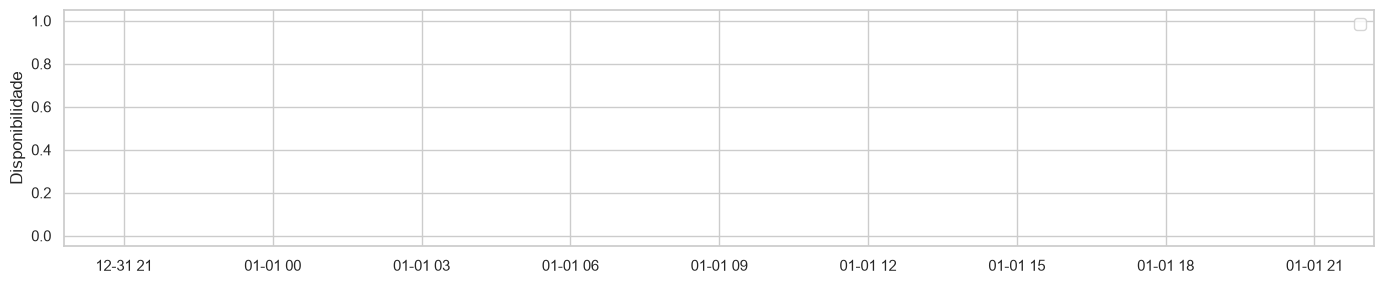

Salvo: D:\UNICAMP\Mestrado\AP539_Aprendizado_estatistico\Trabalho\Projeto\projeto_soft_sensor\dados\02_intermediarios\dados_sincronizados.csv (8640, 16)


In [5]:
dispon=pd.DataFrame({'sensores':dados[['temperatura_interna_C','umidade_relativa_interna_pct']].notna().any(axis=1).astype(int),'api':dados['temperatura_ambiente_C'].notna().astype(int)},index=dados.timestamp)
fig,ax=plt.subplots(figsize=(14,3)); ax.plot(dispon.resample('6h').mean()); ax.set_ylim(-.05,1.05); ax.set_ylabel('Disponibilidade'); ax.legend(); fig.tight_layout(); fig.savefig(ROOT/'resultados/figuras/dados_brutos/01_disponibilidade_fontes.png',dpi=150); plt.show()
out=ROOT/'dados/02_intermediarios/dados_sincronizados.csv'; dados.to_csv(out,index=False,encoding='utf-8-sig'); print('Salvo:',out,dados.shape)

## Conclusões da etapa

Execute todas as células, registre as observações exibidas e confirme os arquivos gerados antes de avançar para o notebook seguinte.